<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Keep uncertainty visible when routing typed answers

**Which tickets would a confidence threshold route automatically, and which still
need review?** We will ask three typed questions in one VGI call per distinct input,
inspect their structured answers, then apply a routing rule in ordinary SQL.

**Synthetic demonstration:** the endpoint is the worker repository's bundled local
mock, copied unchanged. It uses keyword overlap, not an AI model. Its probabilities,
confidence, token counts and model labels are deterministic test values. They do
not demonstrate TypeSafe's production accuracy, calibration, token cost or billing.
No real API key, external inference call or actual ticket routing is involved.

## Choose the routing policy

`MIN_CONFIDENCE` is an inclusive threshold on the returned **confidence** field,
from 0 through 1. Start at 0.80; the experiment lowers it to 0.30. Missing answers
remain unanswered regardless of threshold. This parameter changes the local SQL
policy after inference, not the questions or the mock's scoring.

Restart the kernel and run all after changing it. The two values are illustrative
policies, not recommended production cutoffs.

In [1]:
MIN_CONFIDENCE = 0.80

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import hashlib
import json
from pathlib import Path
from tempfile import TemporaryDirectory
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from fixtures.typesafe_mock import running
from notebook_support import theme, finish, prose

if (
    type(MIN_CONFIDENCE) not in (int, float)
    or not np.isfinite(MIN_CONFIDENCE)
    or not 0 <= MIN_CONFIDENCE <= 1
):
    raise ValueError("MIN_CONFIDENCE must be a finite number from 0 through 1.")
for name, digest in json.loads(Path("fixtures/manifest.json").read_text())["sha256"].items():
    assert hashlib.sha256((Path("fixtures") / name).read_bytes()).hexdigest() == digest
mock_context = running(api_key="notebook-mock-only")
mock = mock_context.__enter__()
mock_url = mock.base_url
assert mock_url.startswith("http://127.0.0.1:")
answers = policy = checks = pd.DataFrame()
theme()
secret_directory = TemporaryDirectory(prefix="vgi-typesafe-secret-store-")
con = haybarn.connect(
    config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False}
)
assert con.execute("SELECT count(*) FROM duckdb_secrets()").fetchall()[0][0] == 0
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-typesafe/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-typesafe/notebooks/pyproject.toml.

## Attach the remote worker and point it at the local fixture

The literal `uvx` location fetches an immutable public Git revision and pinned
compatible SDK packages. No parent worker checkout or local build is required.
An empty temporary secret store prevents existing saved SQL credentials from being loaded.
The visible secret contains a deliberately fake key and the loopback endpoint
started above. The worker resolves this secret before any environment fallback.
Never substitute a real key into a saved notebook.

`models()` here lists the mock's fixed records. A concrete-looking model version
is not evidence that a real model was contacted.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'typesafe' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --from git+https://github.com/Query-farm/vgi-typesafe@c1a121445d9593fae027dccc90ae0ec6ae79ec49 vgi-typesafe');
CREATE SECRET notebook_mock (TYPE typesafe,api_key 'notebook-mock-only',base_url '{{ mock_url }}');
SELECT name,description FROM typesafe.main.models() ORDER BY name;

,name,description
0,jev-latest,The latest iteration of TypeSafe's System One ...
1,jev-preview,A preview version of `jev-latest`: should be b...


## Establish the input population and inspect the output schema

Nine authored records include a repeated message, a tie between two teams, an
empty string and a NULL. The duplicate IDs represent different tickets; preserve
both even if inference is reused. NULL means no input; the empty string is still
content to this worker and is sent to the endpoint.

`DESCRIBE` binds the question types without sending a System One request. A named
question becomes a named STRUCT column; the three question types have different
shapes, so they belong in a STRUCT keyed by question name, not a heterogeneous list.

In [4]:
%%sql
CREATE TABLE tickets AS SELECT * FROM (VALUES
 (1,'package delivery lost urgent delay'),(2,'invoice charge billing'),
 (3,'return refund damaged'),(4,'package invoice'),(5,'package'),
 (6,'Thanks'),(7,''),(8,NULL),(9,'package delivery lost urgent delay')
) AS t(ticket_id,body);
SELECT ticket_id,CASE WHEN body IS NULL THEN '[NULL]' WHEN body='' THEN '[empty string]' ELSE body END AS input FROM tickets ORDER BY ticket_id;
DESCRIBE SELECT * FROM typesafe.main.ask('example',questions:={
 'team':{'type':'choice','instructions':'Which team?',
         'criteria':{'shipping':'Packages','billing':'Invoices','returns':'Refunds'}},
 'urgent':{'type':'noul','instructions':'Urgent?'},
 'severity':{'type':'score','instructions':'How severe?',
             'criteria':['routine question','disruptive delay','critical outage']}
});

,column_name,column_type,null,key,default,extra
0,severity,"STRUCT(score DOUBLE, confidence DOUBLE, probab...",YES,None,None,None
1,usage,"STRUCT(model VARCHAR, input_tokens BIGINT, out...",YES,None,None,None


In [5]:
assert len(mock.requests) == 0
prose(
    "**Schema inspection issued zero System One requests.** The model-list request is a separate read endpoint and is not counted in this ledger."
)

**Schema inspection issued zero System One requests.** The model-list request is a separate read endpoint and is not counted in this ledger.

## Ask all three questions once, then work from the materialized answers

The LATERAL call pairs each input with its answer. We explicitly pass only `body`;
including the ticket ID in state would make the two repeated messages different
states. Materializing this expensive operation prevents display and plotting from
asking again.

`choice` provides an option, a confidence value and a full distribution. `noul`
returns a yes/no probability, while `score` returns a weighted position on an
ordered scale, which need not be an integer. None of those three numbers can be
used interchangeably.

In [6]:
%%sql
CREATE TABLE answered AS
SELECT t.*,a.team.choice AS team,a.team.confidence AS confidence,
 a.team.probabilities AS probabilities,a.urgent.noul AS urgent_probability,
 a.severity.score AS severity_position,a.severity.confidence AS severity_confidence,
 a.usage.model AS model,a.usage.input_tokens AS input_tokens,a.usage.output_tokens AS output_tokens
FROM tickets t,LATERAL typesafe.main.ask(t.body,questions:={
 'team':{'type':'choice','instructions':'Which team should handle this?',
 'criteria':{'shipping':'Delivery status, delays, lost packages',
             'billing':'Charges, invoices, payment problems',
             'returns':'Exchanges, refunds, wrong or damaged items'}},
 'urgent':{'type':'noul','instructions':'Does this message mention urgent delay outage?'},
 'severity':{'type':'score','instructions':'How severe is this?',
             'criteria':['routine question','disruptive delay','critical outage']}
}) a;
SELECT ticket_id,team,round(confidence,4) AS confidence,
 round(urgent_probability,4) AS urgent_probability,
 round(severity_position,4) AS severity_position,round(severity_confidence,4) AS severity_confidence,
 model,input_tokens,output_tokens FROM answered ORDER BY ticket_id;

,ticket_id,team,confidence,urgent_probability,severity_position,severity_confidence,model,input_tokens,output_tokens
0,1,shipping,0.9945,0.9526,1.0,0.3942,jev-1.13.0,63,3
1,2,billing,0.9686,0.2689,1.0,0.0000,jev-1.13.0,61,3
2,3,returns,0.9686,0.2689,1.0,0.0000,jev-1.13.0,61,3
3,4,shipping,0.1941,0.2689,1.0,0.0000,jev-1.13.0,60,3
4,5,shipping,0.3942,0.2689,1.0,0.0000,jev-1.13.0,59,3
5,6,shipping,0.0000,0.2689,1.0,0.0000,jev-1.13.0,59,3
6,7,shipping,0.0000,0.2689,1.0,0.0000,jev-1.13.0,58,3
7,8,None,NaN,NaN,NaN,NaN,None,<NA>,<NA>
8,9,shipping,0.9945,0.9526,1.0,0.3942,jev-1.13.0,63,3


## Compare the distribution with confidence

In this **mock**, confidence is one minus entropy normalized by the number of
options. It is a concentration measure, not the winning probability. Equal scores
break toward the first listed option, so a returned team is not proof that the
input contains evidence for that team. Uniform distributions yield confidence zero.

The chart includes only answered records; ticket 8 stays explicitly unanswered.
For the score question, a uniform three-level distribution has a weighted position
near 1 with zero confidence. Calling that an unambiguous “disruptive delay” would
misread the returned value.

In [7]:
%%sql answers <<
SELECT ticket_id,body,team,confidence,probabilities['shipping'] AS shipping,
 probabilities['billing'] AS billing,probabilities['returns'] AS returns,
 list_max(map_values(probabilities)) AS winning_probability
FROM answered ORDER BY ticket_id;

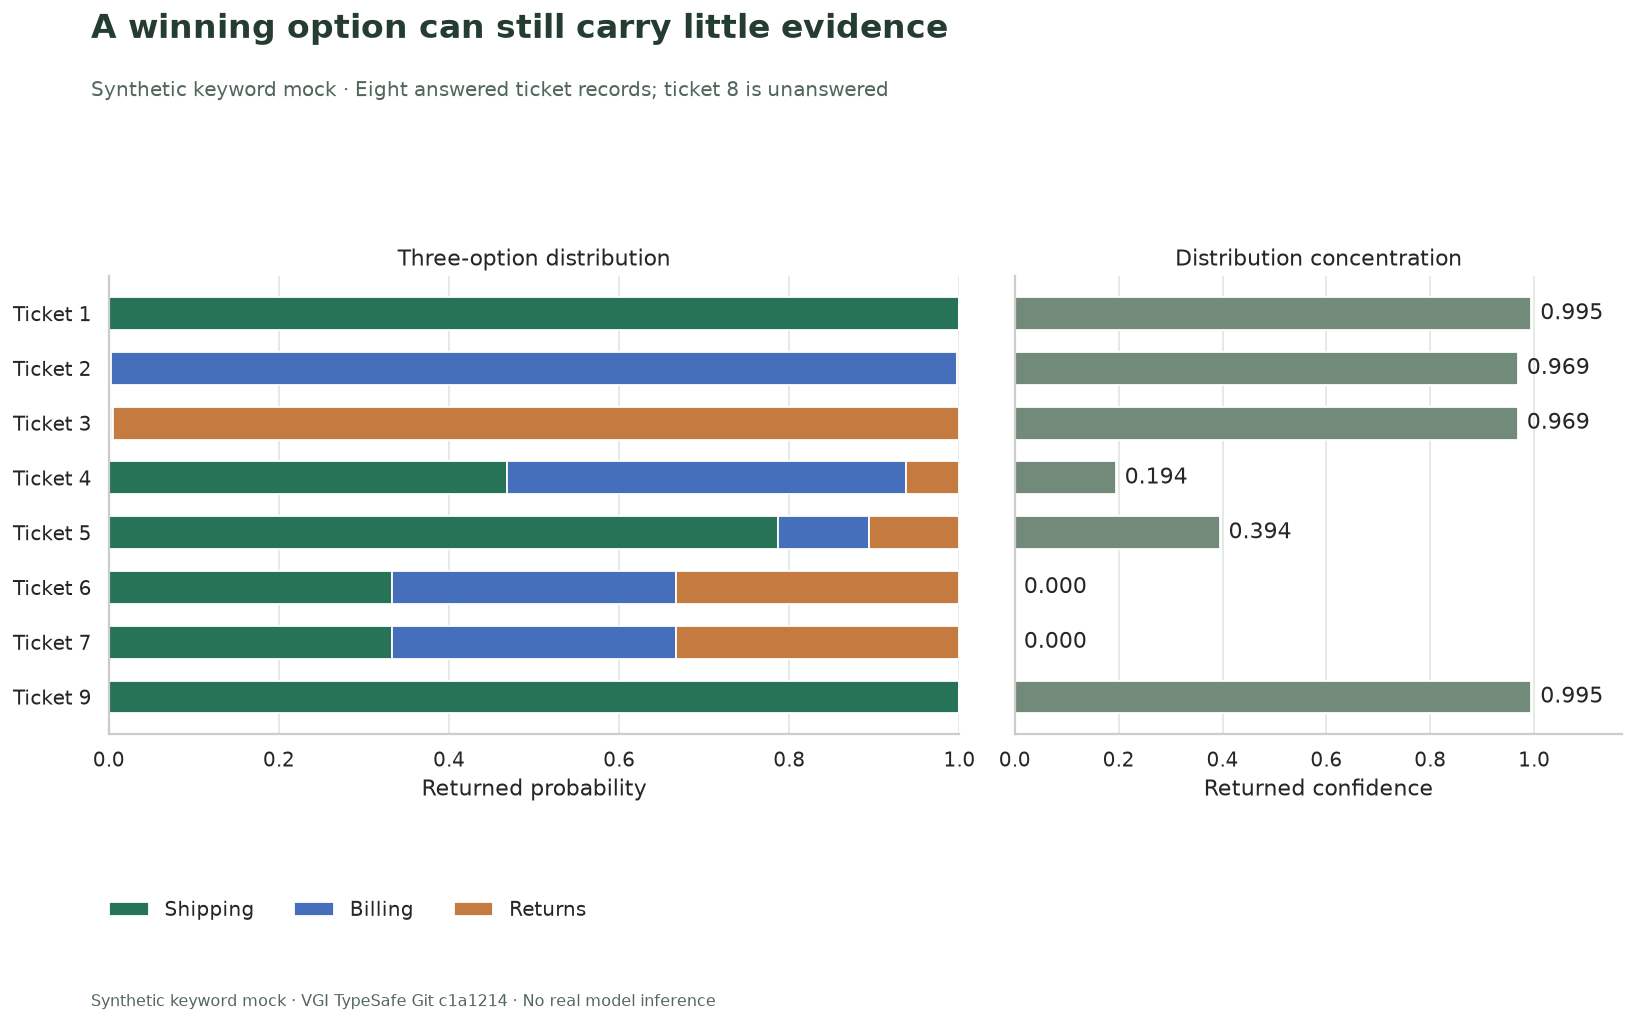

**Ticket 5: winning probability 0.787, confidence 0.394.** Tickets 6 and 7 have uniform distributions and a first-option tie-break. Those returned shipping labels should not be read as confident decisions. The repeated message retains two ticket rows with identical distributions.

In [8]:
chart_rows = answers[answers.team.notna()].copy()
labels = [f"Ticket {i}" for i in chart_rows.ticket_id]
fig, axes = plt.subplots(1, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [1.4, 1]}, sharey=True)
left = np.zeros(len(chart_rows))
for name, color in [("shipping", "#267358"), ("billing", "#456fba"), ("returns", "#c57b40")]:
    axes[0].barh(labels, chart_rows[name], left=left, color=color, height=0.6, label=name.title())
    left += chart_rows[name].to_numpy()
axes[0].set(xlim=(0, 1), xlabel="Returned probability", title="Three-option distribution")
axes[1].barh(labels, chart_rows.confidence, color="#728a7a", height=0.6)
axes[1].bar_label(axes[1].containers[0], fmt="%.3f", padding=5)
axes[1].set(xlim=(0, 1.17), xlabel="Returned confidence", title="Distribution concentration")
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0.08, 0.09),
    ncol=3,
    frameon=False,
)
finish(
    fig,
    "A winning option can still carry little evidence",
    "Synthetic keyword mock · Eight answered ticket records; ticket 8 is unanswered",
    "01_distributions.png",
    bottom=0.20,
)
p = chart_rows[chart_rows.ticket_id == 5].iloc[0]
prose(
    f"**Ticket 5: winning probability {p.winning_probability:.3f}, confidence {p.confidence:.3f}.** "
    "Tickets 6 and 7 have uniform distributions and a first-option tie-break. Those returned shipping labels should not be read as confident decisions. "
    "The repeated message retains two ticket rows with identical distributions."
)

## Apply the policy without changing the answers

Use the named confidence field and an inclusive comparison. Missing answers are
classified before comparison so NULL never becomes an automatic route or a zero
confidence score. The second chart counts ticket records, not distinct request
bodies. This is a local proposed disposition; no ticket system is updated.

In [9]:
%%sql
CREATE TABLE dispositions AS SELECT *,
 CASE WHEN team IS NULL THEN 'Unanswered'
      WHEN confidence >= {{ MIN_CONFIDENCE }} THEN 'Automatic'
      ELSE 'Review' END AS disposition
FROM answered;
SELECT ticket_id,team,round(confidence,4) AS confidence,disposition
FROM dispositions ORDER BY ticket_id;

,ticket_id,team,confidence,disposition
0,1,shipping,0.9945,Automatic
1,2,billing,0.9686,Automatic
2,3,returns,0.9686,Automatic
3,4,shipping,0.1941,Review
4,5,shipping,0.3942,Review
5,6,shipping,0.0000,Review
6,7,shipping,0.0000,Review
7,8,None,NaN,Unanswered
8,9,shipping,0.9945,Automatic


In [10]:
%%sql policy <<
SELECT coalesce(team,'Unanswered') AS team,
 count(*) FILTER(WHERE disposition='Automatic') AS automatic,
 count(*) FILTER(WHERE disposition='Review') AS review,
 count(*) FILTER(WHERE disposition='Unanswered') AS unanswered
FROM dispositions GROUP BY team ORDER BY team;

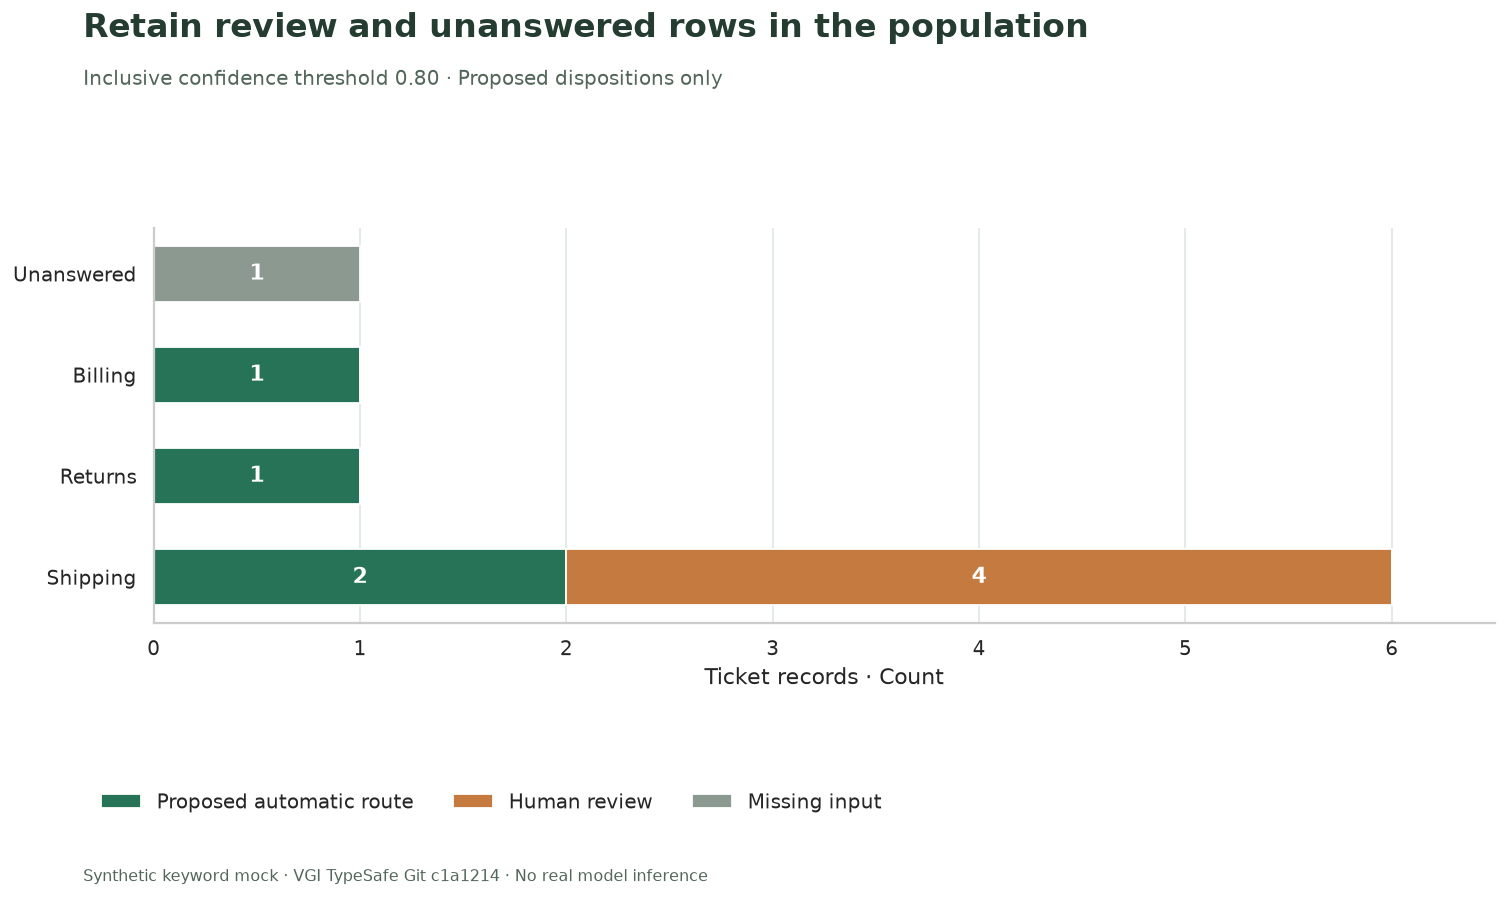

**4 automatic, 4 review, 1 unanswered:** all nine ticket records remain accounted for. Lowering the threshold changes this partition without adding evidence or improving the underlying answers.

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(policy))
for column, label, color in [
    ("automatic", "Proposed automatic route", "#267358"),
    ("review", "Human review", "#c57b40"),
    ("unanswered", "Missing input", "#8c9991"),
]:
    bars = ax.barh(
        policy.team.str.title(), policy[column], left=left, color=color, height=0.55, label=label
    )
    for rect, value in zip(bars, policy[column], strict=True):
        if value:
            ax.text(
                rect.get_x() + rect.get_width() / 2,
                rect.get_y() + rect.get_height() / 2,
                str(int(value)),
                ha="center",
                va="center",
                color="white",
                weight="bold",
            )
    left += policy[column].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, max(left) + 0.5)
ax.set_xlabel("Ticket records · Count")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0.08, 0.08),
    ncol=3,
    frameon=False,
)
finish(
    fig,
    "Retain review and unanswered rows in the population",
    f"Inclusive confidence threshold {MIN_CONFIDENCE:.2f} · Proposed dispositions only",
    "02_routing_policy.png",
    bottom=0.21,
)
prose(
    f"**{int(policy.automatic.sum())} automatic, {int(policy.review.sum())} review, {int(policy.unanswered.sum())} unanswered:** "
    "all nine ticket records remain accounted for. Lowering the threshold changes this partition without adding evidence or improving the underlying answers."
)

## Reconcile rows with actual local requests

This run's fixture records each accepted System One request. Its ledger lets us
verify three questions per request, no request for NULL, and reuse of the repeated
body. Deduplication is scoped to the worker/engine execution path; do not assume a
global cache across separate queries or kernels.

Per-row usage repeats when an answer is reused. Summing those copied usage fields
would not count distinct requests. The local mock's counters are not a production
invoice, and the separate model-list GET is not part of this request ledger.

In [12]:
requests = pd.DataFrame(
    [
        {
            "request_id": i + 1,
            "state": r["state"],
            "questions": len(r["questions"]),
            "requested_model": r["model"],
        }
        for i, r in enumerate(mock.requests)
    ]
)
con.register("_request_frame", requests)
con.execute("CREATE TABLE mock_requests AS SELECT * FROM _request_frame")
con.unregister("_request_frame")
assert sorted(requests.state.tolist()) == sorted(answers.body.dropna().unique().tolist())
assert requests.questions.eq(3).all()
request_count = len(mock.requests)

In [13]:
%%sql
SELECT (SELECT count(*) FROM tickets) AS ticket_records,
 (SELECT count(*) FROM answered WHERE team IS NOT NULL) AS answered_records,
 count(*) AS system_one_requests,sum(questions) AS requested_questions
FROM mock_requests;
SELECT state,questions,requested_model FROM mock_requests ORDER BY state;

,state,questions,requested_model
0,,3,jev-latest
1,Thanks,3,jev-latest
2,invoice charge billing,3,jev-latest
3,package,3,jev-latest
4,package delivery lost urgent delay,3,jev-latest
5,package invoice,3,jev-latest
6,return refund damaged,3,jev-latest


In [14]:
%%sql checks <<
SELECT 'One answer row per ticket' AS check_name,count(*)=9 AND count(DISTINCT ticket_id)=9 AS passed FROM answered
UNION ALL SELECT 'NULL input preserves NULL answers',team IS NULL AND confidence IS NULL AND urgent_probability IS NULL AND severity_position IS NULL AND model IS NULL FROM answered WHERE body IS NULL
UNION ALL SELECT 'Empty string remains answered',team IS NOT NULL FROM answered WHERE body=''
UNION ALL SELECT 'Choice values stay within criteria',bool_and(team IN ('shipping','billing','returns')) FROM answered WHERE body IS NOT NULL
UNION ALL SELECT 'Probability sums within rounding tolerance',bool_and(abs(list_sum(map_values(probabilities))-1)<0.000002) FROM answered WHERE body IS NOT NULL
UNION ALL SELECT 'Confidence within unit interval',bool_and(confidence BETWEEN 0 AND 1) FROM answered WHERE body IS NOT NULL
UNION ALL SELECT 'Yes/no probability within unit interval',bool_and(urgent_probability BETWEEN 0 AND 1) FROM answered WHERE body IS NOT NULL
UNION ALL SELECT 'Score stays on declared zero-to-two scale',bool_and(severity_position BETWEEN 0 AND 2) FROM answered WHERE body IS NOT NULL
UNION ALL SELECT 'Repeated bodies retain identical answers',a.team=b.team AND a.probabilities=b.probabilities AND a.confidence=b.confidence FROM answered a JOIN answered b ON a.ticket_id=1 AND b.ticket_id=9
UNION ALL SELECT 'Every ticket receives one disposition',count(*)=9 AND count(DISTINCT ticket_id)=9 FROM dispositions
UNION ALL SELECT 'Automatic routes meet selected threshold',coalesce(bool_and(confidence >= {{ MIN_CONFIDENCE }}),true) FROM dispositions WHERE disposition='Automatic'
UNION ALL SELECT 'Request ledger covers distinct non-NULL bodies',count(*)=(SELECT count(DISTINCT body) FROM tickets) AND count(DISTINCT state)=count(*) FROM mock_requests;

In [15]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all(), checks
assert int(policy[["automatic", "review", "unanswered"]].to_numpy().sum()) == len(answers)
assert len(mock.requests) == request_count
prose(
    f"**All {len(checks)} relationship checks passed.** The ledger contains {request_count} System One requests; plotting and policy evaluation made no further requests."
)

,check_name,passed
0,One answer row per ticket,True
1,NULL input preserves NULL answers,True
2,Empty string remains answered,True
3,Choice values stay within criteria,True
4,Probability sums within rounding tolerance,True
5,Confidence within unit interval,True
6,Yes/no probability within unit interval,True
7,Score stays on declared zero-to-two scale,True
8,Repeated bodies retain identical answers,True
9,Every ticket receives one disposition,True


**All 12 relationship checks passed.** The ledger contains 7 System One requests; plotting and policy evaluation made no further requests.

## Try one controlled change

Set **`MIN_CONFIDENCE = 0.30`**, restart the kernel and run all. Predict which ticket
will move from review to automatic routing, then compare the disposition table and
second chart. The distribution chart and underlying answers should stay identical.
The NULL input should still be unanswered.

This illustrates how a SQL threshold changes coverage. It does not establish a
safe accuracy/coverage tradeoff: that would require labelled evaluation data and
real model outputs, plus a policy for unresolved cases. Reset
**`MIN_CONFIDENCE = 0.80`** to reproduce the saved run.

In [16]:
con.close()
mock_context.__exit__(None, None, None)
secret_directory.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup](README.md)